# Credit Scoring Model (CodeAlpha ML Internship - Task 1)
Goal: predict whether a loan applicant is a **good** or **bad** credit risk from past financial data.
Dataset: Statlog German Credit Data (UCI), 1000 applicants, 20 features.
Models: Logistic Regression, Decision Tree, Random Forest.
Metrics: Precision, Recall, F1-Score, ROC-AUC.

In [ ]:
%pip install ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay, precision_recall_curve)
RANDOM_STATE = 42

## 1. Load data
The target is converted so that **1 = bad credit (high risk)** and **0 = good credit**.
This way "Recall" tells us how many risky applicants we manage to catch.

In [2]:
data = fetch_ucirepo(id=144)   # Statlog (German Credit Data)
X = data.data.features.copy()
y = (data.data.targets.iloc[:, 0] == 2).astype(int)   # original: 1 = good, 2 = bad

X.columns = ["checking_status", "duration_months", "credit_history", "purpose", "credit_amount",
             "savings", "employment_since", "installment_rate", "personal_status_sex",
             "other_debtors", "residence_since", "property", "age", "other_installment_plans",
             "housing", "existing_credits", "job", "num_dependents", "telephone", "foreign_worker"]
print(X.shape)
print("Target (1 = bad credit):\n", y.value_counts())
print("Missing values:", X.isna().sum().sum())
X.head()

(1000, 20)
Target (1 = bad credit):
 class
0    700
1    300
Name: count, dtype: int64
Missing values: 0


,checking_status,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


## 2. EDA

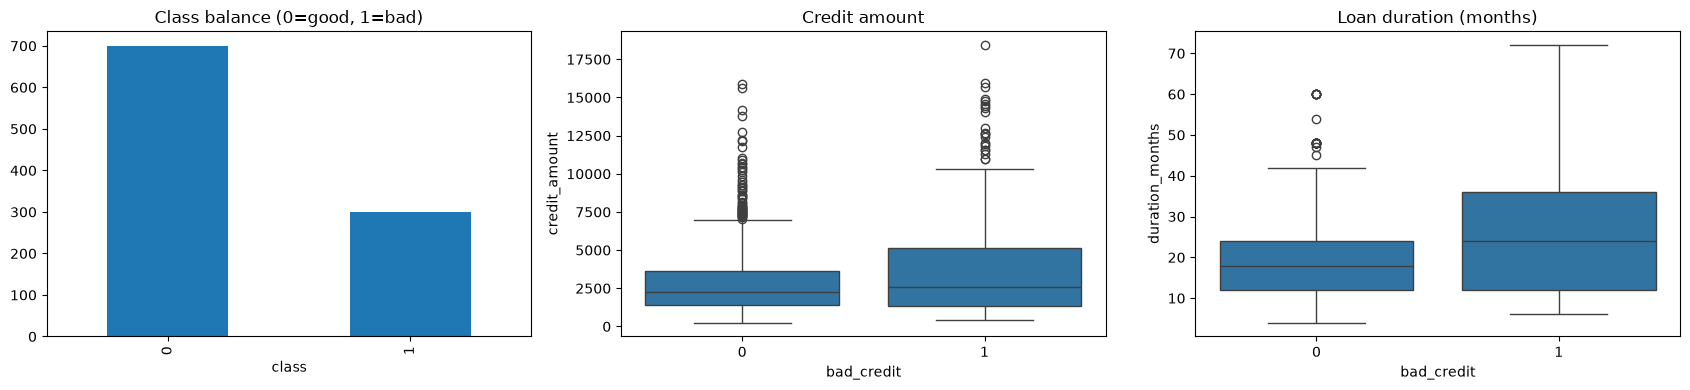

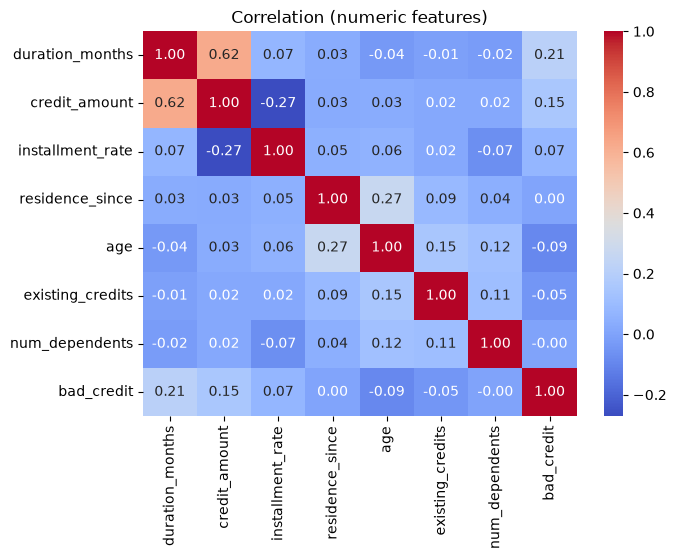

In [3]:
df = X.assign(bad_credit=y)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
y.value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Class balance (0=good, 1=bad)")
sns.boxplot(data=df, x="bad_credit", y="credit_amount", ax=ax[1]); ax[1].set_title("Credit amount")
sns.boxplot(data=df, x="bad_credit", y="duration_months", ax=ax[2]); ax[2].set_title("Loan duration (months)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation (numeric features)"); plt.show()

## 3. Feature engineering
The dataset has no income column, so we build proxy features from the financial history:
- `monthly_payment`: credit amount / duration
- `payment_burden`: monthly payment x installment rate (installment rate = % of disposable income),
  used as a debt-to-income proxy
- `amount_per_age`: credit amount relative to age
- `long_loan`: 1 if duration > 24 months
- `log_amount`: log of credit amount (reduces skew)
- `age_group`: young / adult / senior

In [4]:
def add_features(d):
    d = d.copy()
    d["monthly_payment"] = d["credit_amount"] / d["duration_months"]
    d["payment_burden"] = d["monthly_payment"] * d["installment_rate"]
    d["amount_per_age"] = d["credit_amount"] / d["age"]
    d["long_loan"] = (d["duration_months"] > 24).astype(int)
    d["log_amount"] = np.log1p(d["credit_amount"])
    d["age_group"] = pd.cut(d["age"], [0, 25, 40, 120], labels=["young", "adult", "senior"]).astype(str)
    return d

X_fe = add_features(X)
cat_cols = X_fe.select_dtypes(exclude="number").columns.tolist()
num_cols = X_fe.select_dtypes("number").columns.tolist()
print(len(num_cols), "numeric,", len(cat_cols), "categorical features")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
X_train, X_test, y_train, y_test = train_test_split(
    X_fe, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

12 numeric, 14 categorical features


## 4. Train and compare models
Classes are imbalanced (70% good / 30% bad), so we use `class_weight="balanced"`.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            class_weight="balanced", random_state=RANDOM_STATE),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
fitted, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    pred, proba = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    rows.append({"Model": name, "CV ROC-AUC": cv_auc,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "Test ROC-AUC": roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("Test ROC-AUC", ascending=False)
results

,CV ROC-AUC,Accuracy,Precision,Recall,F1,Test ROC-AUC
Model,,,,,,
Logistic Regression,0.766,0.755,0.565,0.800,0.662,0.810
Random Forest,0.795,0.745,0.562,0.683,0.617,0.800
Decision Tree,0.697,0.605,0.402,0.650,0.497,0.635


## 5. ROC curves and confusion matrices

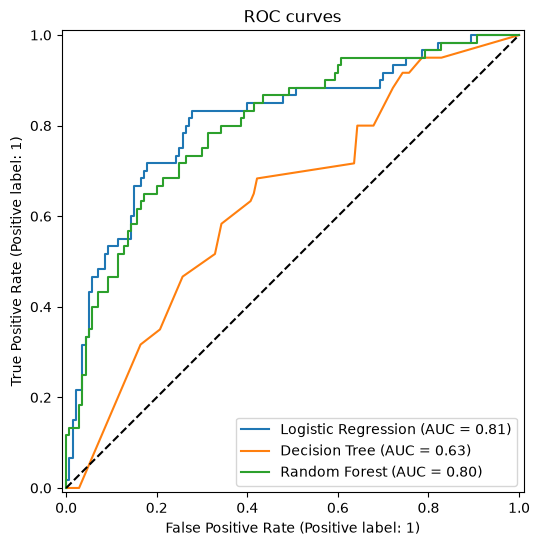

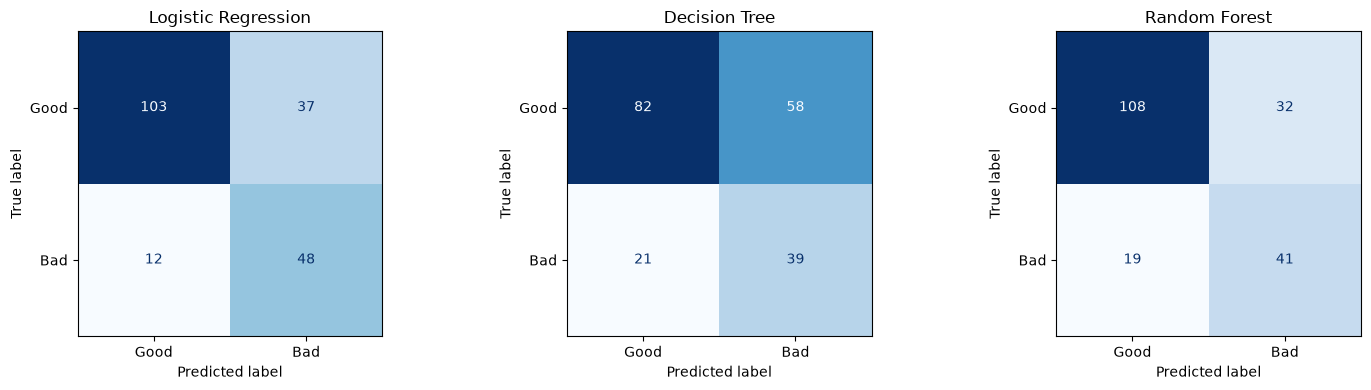

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--"); ax.set_title("ROC curves"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False,
                                          cmap="Blues", display_labels=["Good", "Bad"])
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 6. Tune Random Forest

In [7]:
grid = GridSearchCV(
    Pipeline([("prep", preprocess),
              ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
    {"clf__n_estimators": [200, 400], "clf__max_depth": [4, 6, 10, None],
     "clf__min_samples_leaf": [1, 3, 5]},
    cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
best = grid.best_estimator_
print("Best params:", grid.best_params_, "| CV AUC:", round(grid.best_score_, 3))
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=["Good credit", "Bad credit"]))
print("Test ROC-AUC:", round(roc_auc_score(y_test, best.predict_proba(X_test)[:, 1]), 3))

Best params: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200} | CV AUC: 0.798
              precision    recall  f1-score   support

 Good credit       0.87      0.81      0.84       140
  Bad credit       0.61      0.72      0.66        60

    accuracy                           0.78       200
   macro avg       0.74      0.76      0.75       200
weighted avg       0.79      0.78      0.78       200

Test ROC-AUC: 0.81


## 7. Decision threshold
For a bank, approving a bad applicant costs much more than rejecting a good one.
We pick the threshold using cross-validated predictions on the **training** set only
(so the test set stays untouched), then apply it to the test set.

In [8]:
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_thr = thr[np.argmax(f1s)]
proba_test = best.predict_proba(X_test)[:, 1]
print(f"Chosen threshold: {best_thr:.2f}")
for t, label in [(0.5, "default 0.5"), (best_thr, "tuned")]:
    p = (proba_test >= t).astype(int)
    print(f"{label:12s} thr={t:.2f}  precision={precision_score(y_test, p):.3f}  "
          f"recall={recall_score(y_test, p):.3f}  f1={f1_score(y_test, p):.3f}")

Chosen threshold: 0.43
default 0.5  thr=0.50  precision=0.614  recall=0.717  f1=0.662
tuned        thr=0.43  precision=0.474  recall=0.750  f1=0.581


## 8. Feature importance

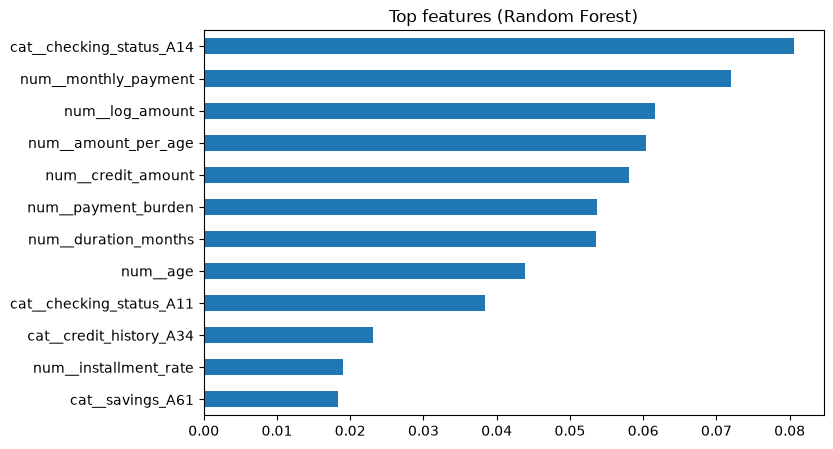

In [9]:
names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["clf"].feature_importances_, index=names).sort_values().tail(12)
imp.plot(kind="barh", figsize=(8, 5), title="Top features (Random Forest)"); plt.show()

## 9. Save model

In [10]:
joblib.dump(best, "credit_scoring_model.joblib")
print("Saved credit_scoring_model.joblib")

Saved credit_scoring_model.joblib


## Conclusion
Write here: best model, key metrics (Precision, Recall, F1, ROC-AUC), top features, and the effect of the threshold.

Three models were compared on the German Credit dataset (1000 applicants, 20% held out for testing, 60 bad-credit cases in the test set). Class weights were balanced because only 30% of applicants are bad credit risks. Logistic Regression gave the best recall for bad credit (0.80), F1 (0.66) and test ROC-AUC (0.81), while Random Forest had the best cross-validated ROC-AUC (0.795). A tuned Random Forest (max_depth=10, n_estimators=200) reached test ROC-AUC 0.81, accuracy 0.78, and caught 72% of bad-credit applicants with 61% precision. The Decision Tree was clearly the weakest (ROC-AUC 0.64).

Lowering the decision threshold to 0.43 raised recall slightly (0.72 to 0.75) but reduced precision (0.61 to 0.47) and F1, so it did not clearly help. The best threshold in practice depends on how a bank weighs the cost of approving a bad applicant against rejecting a good one.

The most important features were the checking account status (no checking account), monthly payment, log of credit amount, amount per age and credit amount. Four of the top seven features were engineered by us, which shows the value of feature engineering from financial history. Because the test set is small, differences between Logistic Regression and Random Forest are not conclusive.
